# 03 · Patterns of a healthy machine

**Goal:** learn what "normal" looks like before I look for faults. A fault is a change from normal, so I need to know how much normal already moves: during the day, with the weather, from machine to machine and over the months.

**How to read this notebook.** Same pattern as before: a question, short code cells, then `Obs:` and `Decision:`.

I only use **healthy rows**: cleaned data (`clean_sensors()`, notebook 02), fan on, and no fault label. These are the rows the model must learn to leave alone.

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

from ahu_fdd.data import add_building, clean_sensors, label_rows, load_labels, load_sensors
from ahu_fdd.features import minutes_since_fan_on
from ahu_fdd.plots import BUILDING_COLORS, save_fig, set_style

set_style()  # same look for every chart

In [2]:
# Cleaned train and test data, with building and fault label (test has no labels)
labels = load_labels()
train = add_building(clean_sensors(load_sensors("train")))
train["label"] = label_rows(train, labels)
test = add_building(clean_sensors(load_sensors("test")))

# Healthy rows: fan on and no fault. Hour of the day for the daily profiles
healthy = train[(train["fan_status"] == 1) & (train["label"] == "normal")].copy()
healthy["hour"] = healthy["timestamp"].dt.hour
print(f"Healthy rows: {len(healthy):,} of {len(train):,} train rows")

Healthy rows: 1,287,011 of 2,050,081 train rows


## 1. What does a normal day look like?

**How:** the median of the main signals for each hour of the day, per building. Median, not mean, so a few odd rows don't move the line.

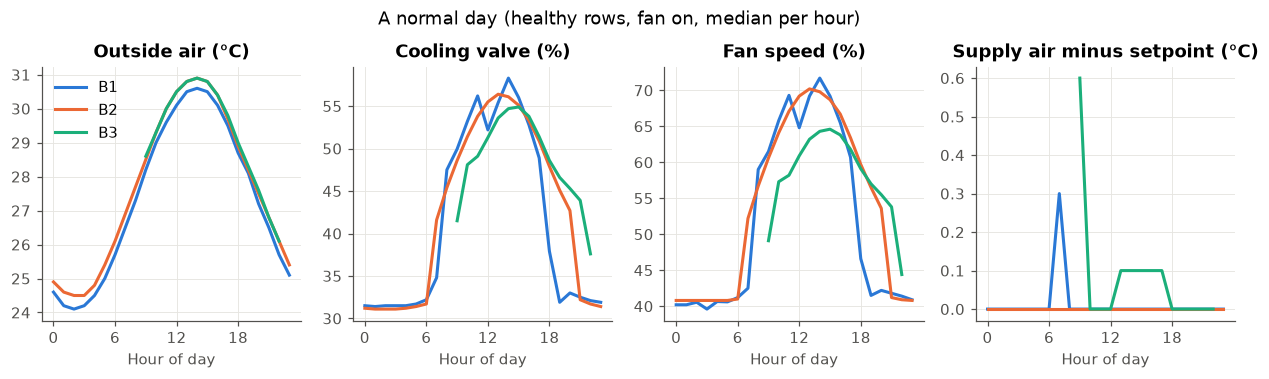

In [3]:
# Hourly median of outside temperature, valve, fan speed and supply air error, per building
healthy["sat_error"] = healthy["sat_c"] - healthy["sat_sp_c"]  # supply air minus its setpoint
signals = {
    "oat_c": "Outside air (°C)",
    "chw_valve_cmd_pct": "Cooling valve (%)",
    "fan_speed_pct": "Fan speed (%)",
    "sat_error": "Supply air minus setpoint (°C)",
}
daily = healthy.groupby(["building", "hour"])[list(signals)].median()

fig, axes = plt.subplots(1, 4, figsize=(14, 3), sharex=True)
for ax, (col, title) in zip(axes, signals.items(), strict=True):
    for building in ["B1", "B2", "B3"]:
        ax.plot(daily.loc[building, col], color=BUILDING_COLORS[building], label=building)
    ax.set_title(title)
    ax.set_xticks(range(0, 24, 6))
    ax.set_xlabel("Hour of day")
axes[0].legend()
fig.suptitle("A normal day (healthy rows, fan on, median per hour)", y=1.05)
save_fig(fig, "03_normal_day")
plt.show()

**How to read the chart:** each line is the typical value at that hour. Outside air goes from about 26 °C at night to 31 °C in the afternoon. The cooling valve and the fan follow it: they work harder in the afternoon, when it's hot and the buildings are full. The supply air stays close to its setpoint all day (the line is near 0), except at the hour each building starts its machines (07:00 office, 09:00 mall), where it goes up. The office valve and fan dip at 12:00: lunch time, fewer people.

**Obs:** a healthy machine follows the weather and the occupancy. The valve going from 30% at night to 60% in the afternoon is normal. The only time the supply air is far from its setpoint is when the machine has just started.

## 2. Setpoints and start-up

Two things that change the meaning of a value:
- The **setpoint** is the temperature the machine is told to give. If setpoints differ between machines, 14 °C can be fine for one machine and too warm for another.
- At **start-up** the air in the duct is warm and the machine needs some minutes to cool it down.

In [4]:
# Does each machine always have the same setpoints?
setpoint_cols = ["sat_sp_c", "supply_static_sp_pa", "zone_temp_sp_c"]
n_values = healthy.groupby("ahu_id")[setpoint_cols].nunique()
print("Different values per machine (max):", n_values.max().to_dict())
healthy.groupby("building")["sat_sp_c"].agg(["min", "max"])

Different values per machine (max): {'sat_sp_c': 1, 'supply_static_sp_pa': 1, 'zone_temp_sp_c': 1}


,min,max
building,,
B1,12.5,14.5
B2,12.5,14.5
B3,12.5,14.5


**How to read it:** every machine has one fixed value for each setpoint (max 1 different value per machine). But the supply air setpoint is not the same for all machines: it goes from 12.5 to 14.5 °C.

**Decision:** I never use `sat_c` alone. I use the error `sat_c - sat_sp_c`, so 14 °C means "on target" for a machine with setpoint 14 and "1.5 °C too warm" for a machine with setpoint 12.5.

In [5]:
# Supply air error by minutes since the fan started
# (minutes_since_fan_on() is in src/ahu_fdd/features.py)
on_rows = train[(train["fan_status"] == 1) & (train["label"] == "normal")].copy()
on_rows["minutes_on"] = minutes_since_fan_on(train).loc[on_rows.index]
on_rows["sat_error"] = on_rows["sat_c"] - on_rows["sat_sp_c"]
bins = [0, 15, 30, 60, 120, float("inf")]
names = ["0-15 min", "15-30 min", "30-60 min", "1-2 h", "more than 2 h"]
on_rows["since_start"] = pd.cut(on_rows["minutes_on"], bins, labels=names, right=False)
on_rows.groupby("since_start", observed=True)["sat_error"].agg(["mean", "std", "size"]).round(2)

,mean,std,size
since_start,,,
0-15 min,4.94,2.04,11256
15-30 min,1.10,0.51,11256
30-60 min,0.15,0.26,22518
1-2 h,0.10,0.44,45027
more than 2 h,0.08,0.46,1196954


**How to read it:** in the first 15 minutes after the fan starts, the supply air is on average 4.9 °C above its setpoint. From 15 to 30 minutes it's 1.1 °C, and after 30 minutes it stays around 0.1 °C. (The 24/7 machines almost never start, so most of these rows are from the office and the mall.)

**Obs:** every start-up looks like a short "weak radiator" (warm air, valve open). It is normal and it happens every day.

**Decision:** in the model, I won't raise an alarm in the first 30 minutes after a start. `minutes_since_fan_on()` will be a feature or a filter.

## 3. What moves the cooling valve? And the afternoon storms

**How:** correlation of the valve with the other signals, then a look at sudden drops in outside temperature (Singapore has afternoon thunderstorms).

In [6]:
# Correlation of the valve with fan speed, outside air and return air, per building
drivers = ["fan_speed_pct", "oat_c", "rat_c"]
corr = healthy.groupby("building")[["chw_valve_cmd_pct", *drivers]].corr()
corr.xs("chw_valve_cmd_pct", level=1)[drivers].round(2)

,fan_speed_pct,oat_c,rat_c
building,,,
B1,0.93,0.51,-0.11
B2,0.94,0.74,0.12
B3,0.93,0.22,-0.06


**How to read it:** 1 means they always move together, 0 means no link. The valve moves almost exactly with the fan speed (0.93 in every building): when the load goes up, the controllers open both. Outside air matters more in the hospital (0.74) than in the mall (0.22), probably because the mall load depends more on people than on weather.

**Obs:** "how open the valve is" only makes sense next to "how much air the fan moves" and "how hot it is". A valve at 60% can be normal on a hot afternoon and suspicious at night.

In [7]:
# Storms: outside air falls more than 2.5 °C in 30 minutes (mall sensor, same weather for all)
mall_oat = train[train["building"] == "B3"].groupby("timestamp")["oat_c"].mean()
fall_30min = mall_oat - mall_oat.shift(-6)
storm_rows = fall_30min[fall_30min > 2.5]

# Rows less than 3 hours apart belong to the same storm
storm_id = (storm_rows.index.to_series().diff() > pd.Timedelta("3h")).cumsum()
storms = storm_rows.groupby(storm_id.values).apply(lambda s: s.index.min())
print(f"Storms in train: {len(storms)} (about {len(storms) / 26:.1f} per week)")
storms.dt.hour.value_counts().sort_index().rename("storms starting at this hour")

Storms in train: 51 (about 2.0 per week)


oat_c
12     2
13     9
14    10
15    10
16     9
17    10
23     1
Name: storms starting at this hour, dtype: int64

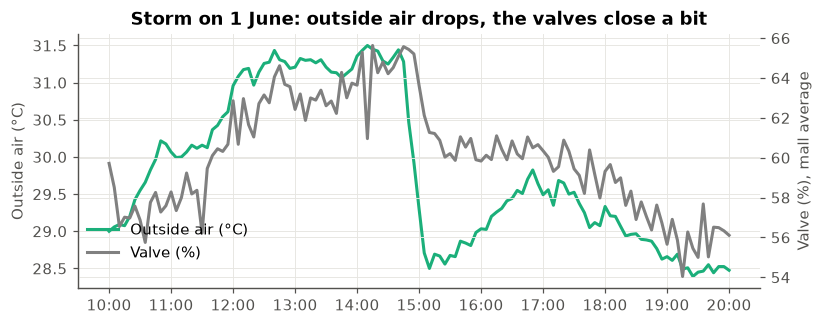

In [8]:
# One storm in detail: 1 June 2025, outside air and the valve of the mall machines
day = slice("2025-06-01 10:00", "2025-06-01 20:00")
mall = train[(train["building"] == "B3") & (train["fan_status"] == 1)].groupby("timestamp")
fig, ax1 = plt.subplots(figsize=(8, 3))
ax1.plot(mall["oat_c"].mean().loc[day], color=BUILDING_COLORS["B3"], label="Outside air (°C)")
ax1.set_ylabel("Outside air (°C)")
ax2 = ax1.twinx()  # second axis only for this picture, to show the timing
ax2.plot(mall["chw_valve_cmd_pct"].mean().loc[day], color="grey", label="Valve (%)")
ax2.set_ylabel("Valve (%), mall average")
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax1.set_title("Storm on 1 June: outside air drops, the valves close a bit")
fig.legend(loc="lower left", bbox_to_anchor=(0.12, 0.15))
plt.show()

**How to read it:** about 51 storms in the six months of train, so around two per week. Almost all start between 13:00 and 18:00, spread evenly over those hours. On 1 June, the outside air falls about 3 °C in a few minutes at 15:00, and the valves of the mall close a few points right after.

**Obs:** a storm changes the load quickly. The valve drops while nothing is broken. A model that looks at single 5-minute rows could see a "stuck" or "weak" pattern there for a few minutes.

**Decision:** outside air (and its change over the last hour) will be a feature, and the persistence rule (alarm only if the signal lasts hours) will filter these short events.

## 4. Are all machines alike?

**How:** for each machine, the share of healthy rows with the valve fully open (100%) and the typical supply air error. A valve at 100% means the machine is giving all the cooling it can.

In [9]:
# Share of healthy rows with the valve at 100%, and the typical supply air error, per machine
healthy["valve_full"] = healthy["chw_valve_cmd_pct"] >= 99.9
per_ahu = healthy.groupby("ahu_id").agg(
    valve_full=("valve_full", "mean"),
    sat_error=("sat_error", "median"),
)
per_ahu.sort_values("valve_full", ascending=False).head(6).astype(float).round(2)

,valve_full,sat_error
ahu_id,,
B1-AHU-05,0.77,1.9
B3-AHU-09,0.67,1.9
B3-AHU-02,0.62,1.5
B1-AHU-01,0.00,0.0
B3-AHU-03,0.00,0.0
B2-AHU-08,0.00,0.0


In [10]:
# Same check per month, for the three machines at the top, in train and test
top3 = ["B1-AHU-05", "B3-AHU-02", "B3-AHU-09"]
both = pd.concat([healthy, test[test["fan_status"] == 1]], ignore_index=True)
both = both[both["ahu_id"].isin(top3)]
both["month"] = both["timestamp"].dt.strftime("%m %b")
monthly = both.groupby(["ahu_id", "month"])["chw_valve_cmd_pct"].apply(lambda v: (v >= 99.9).mean())
monthly.unstack("month").map("{:.0%}".format)

month,01 Jan,02 Feb,03 Mar,04 Apr,05 May,06 Jun,07 Jul,08 Aug
ahu_id,,,,,,,,
B1-AHU-05,75%,74%,77%,77%,81%,77%,79%,82%
B3-AHU-02,58%,64%,57%,64%,67%,63%,60%,69%
B3-AHU-09,65%,65%,67%,64%,71%,68%,69%,74%


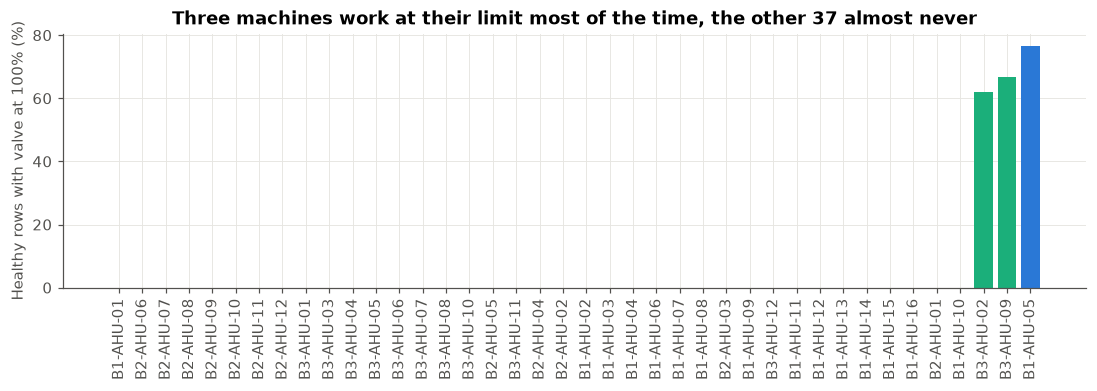

In [11]:
# Picture for the report: share of time with the valve at 100%, every machine
fig, ax = plt.subplots(figsize=(12, 3))
ordered = per_ahu.sort_values("valve_full")
colors = [BUILDING_COLORS[ahu[:2]] for ahu in ordered.index]
ax.bar(ordered.index, ordered["valve_full"] * 100, color=colors)
ax.set_ylabel("Healthy rows with valve at 100% (%)")
ax.tick_params(axis="x", labelrotation=90)
ax.set_title("Three machines work at their limit most of the time, the other 37 almost never")
save_fig(fig, "03_valve_at_limit")
plt.show()

**How to read it:** 37 machines almost never open the valve fully. Three machines (B1-AHU-05 lobby, B3-AHU-02 cinema foyer, B3-AHU-09 retail L2) have it at 100% in 60-80% of their healthy rows, every month, in train and test. When they do, the supply air stays about 2 °C above the setpoint.

**Obs:**
- These three machines look like a permanent weak radiator (`low_coil_capacity`), but the labels say these rows are normal. They are probably too small for their zones: a lobby and a cinema foyer with doors opening all day in a hot climate.
- A model or rule with one global threshold ("valve at 100% and air 2 °C too warm = fault") would alarm on these three machines all the time. This is the kind of repeated false alarm that makes technicians stop trusting alerts.
- These three machines also have labelled faults (for example a weak radiator in B1-AHU-05 in March). So the model has to see the fault as a change from *their* normal, not from the fleet normal.

**Decision:** features must be relative to each machine's own normal: for example, the supply air error compared with the same machine's usual error at that load, not with a fixed number.

**Ask the operator:** Are B1-AHU-05, B3-AHU-02 and B3-AHU-09 known to be undersized or struggling?
Why it matters: if yes, I treat their constant full valve as normal. If not, they may have a long, unlabelled problem.

## 5. Does normal change over the months?

**How:** the filter pressure drop (`filter_dp_pa`) per month, train and test. A filter gets dirtier with time, so it pushes back more air pressure, until someone replaces it.

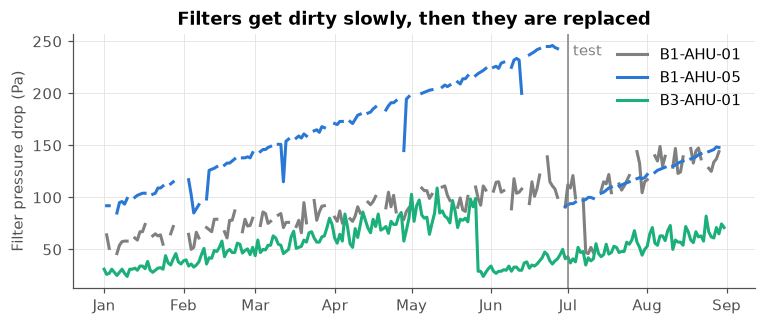

In [12]:
# Monthly median of the filter pressure drop for three machines, train and test (fan on)
fan_on = pd.concat([train, test], ignore_index=True)
fan_on = fan_on[fan_on["fan_status"] == 1]
# One colour per machine here (two of them are in the same building)
sample = {
    "B1-AHU-01": "grey",
    "B1-AHU-05": BUILDING_COLORS["B1"],
    "B3-AHU-01": BUILDING_COLORS["B3"],
}

fig, ax = plt.subplots(figsize=(8, 3))
for ahu_id, color in sample.items():
    one = fan_on[fan_on["ahu_id"] == ahu_id].set_index("timestamp")["filter_dp_pa"]
    ax.plot(one.resample("D").median(), label=ahu_id, color=color)
ax.axvline(pd.Timestamp("2025-07-01"), color="grey", lw=1)
ax.text(pd.Timestamp("2025-07-03"), ax.get_ylim()[1] * 0.92, "test", color="grey")
ax.set_ylabel("Filter pressure drop (Pa)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend()
ax.set_title("Filters get dirty slowly, then they are replaced")
save_fig(fig, "03_filter_drift")
plt.show()

**How to read the chart:** each line is the daily median of one machine. The pressure drop climbs slowly for months (dirt builds up) and then falls in one day (new filter). B1-AHU-05 goes from about 90 Pa in January to about 245 Pa at the end of June, and drops to about 95 Pa on 1 July. B3-AHU-01 is replaced on 28 May and B1-AHU-01 on 9 July (in test). The short dips down are single days with little running time, and the breaks in the office lines are weekends and holidays (fan off all day).

**Obs:** "normal" is not fixed. A dirty filter makes the fan work harder, so fan speed and power slowly change too. This is not one of the four faults, but a model trained in January sees a different machine in August.

**Decision:** I won't use raw filter pressure or fan power as fault signals. If I use them, it will be as a change over the last days, not as an absolute value. And I validate in time order (train on earlier months, check on later ones), so this drift is part of the test.

## 6. Does test look like train?

**How:** typical values per building in train (healthy rows) and test (all rows with the fan on).

In [13]:
# Median per building of the main signals, train healthy vs test
compare = ["oat_c", "chw_valve_cmd_pct", "fan_speed_pct", "sat_c", "rat_c"]
test_on = test[test["fan_status"] == 1]
pd.concat(
    {
        "train": healthy.groupby("building")[compare].median(),
        "test": test_on.groupby("building")[compare].median(),
    },
    axis=1,
).swaplevel(axis=1).sort_index(axis=1).astype(float).round(1)

chw_valve_cmd_pct       fan_speed_pct       oat_c       rat_c        \
                      test train          test train  test train  test train   
building                                                                       
B1                    48.3  47.2          59.8  59.3  29.2  28.9  24.0  24.0   
B2                    40.2  39.9          50.5  50.0  27.6  27.4  24.1  24.1   
B3                    49.4  48.6          58.5  58.3  29.6  29.3  24.0  24.0   

         sat_c        
          test train  
building              
B1        13.9  13.9  
B2        13.5  13.5  
B3        13.7  13.7

**How to read it:** for each signal, the train and test medians sit next to each other. They are very close: test (July-August) is about 0.3 °C warmer outside, and the valves and fans work about 1 point more. Supply and return air are the same.

**Obs:** Singapore has almost no seasons, so test is not a different climate. The main differences between train and test come from the machines themselves (filters, the frozen sensor of notebook 02), not from the weather.

## Summary

- **A normal day:** valve and fan follow the outside temperature and occupancy (valve about 30% at night, 60% in the afternoon). The supply air stays near its setpoint.
- **Setpoints are fixed per machine but differ between machines** (12.5 to 14.5 °C). I use the error `sat_c - sat_sp_c`, never `sat_c` alone.
- **Start-up:** the first 30 minutes look like a fault (supply air up to 5 °C too warm). No alarms there.
- **Storms:** about two per week, in the afternoon. They change the load in minutes. Persistence rules and weather features handle them.
- **Three machines are always at their limit** (B1-AHU-05, B3-AHU-02, B3-AHU-09): valve at 100% most of the time and air 2 °C too warm, labelled normal. A global threshold would alarm on them every day. Features must be relative to each machine's normal.
- **Normal drifts:** filters get dirty for months and are then replaced. I validate in time order and avoid absolute filter or power values.
- **Test looks like train** in weather and typical values.
- Next: `04_faults`, to see how each fault looks against this normal.